In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anoopjohny/traffic-crashes-crashes/Traffic_Crashes_-_Crashes.csv


In [3]:
# Name: YOUR NAME | Roll no: YOUR ROLL NO | Date: 19 Nov 2026
# CELL 1 of 3: setup, load, schema, cleaning + validation functions, tests
import json, random, shutil, sqlite3, time, warnings
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, average_precision_score,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
SAMPLE_SIZE = 100_000   # use 30_000 for a faster first run
RAW_FILE = Path("/kaggle/input/datasets/anoopjohny/traffic-crashes-crashes/Traffic_Crashes_-_Crashes.csv")
BASE = Path("/kaggle/working/project")
for d in ["data/raw", "data/cleaned", "outputs/figures", "outputs/reports", "outputs/models",
          "sql", "docs", "tests", ".github/workflows"]:
    (BASE / d).mkdir(parents=True, exist_ok=True)
FIG, REP = BASE / "outputs/figures", BASE / "outputs/reports"

# ---------- Part A: load (raw file is never edited), sample, unseen rows ----------
if not RAW_FILE.exists():
    raise FileNotFoundError(f"CSV not found: {RAW_FILE}. Add the dataset with 'Add Input'.")
full = pd.read_csv(RAW_FILE, low_memory=False)
full.columns = [c.strip().upper() for c in full.columns]
print("Full raw file:", full.shape)
sample = full.sample(n=min(SAMPLE_SIZE, len(full)), random_state=SEED)
unseen = full.drop(index=sample.index).sample(n=30, random_state=SEED)   # rows the model never sees
unseen.to_csv(BASE / "data/new_rows_example.csv", index=False)
raw = sample.reset_index(drop=True)
raw.to_csv(BASE / "data/raw/crashes_sample.csv", index=False)
del full
print("Sample:", raw.shape)

REQUIRED = ["CRASH_DATE", "POSTED_SPEED_LIMIT", "INJURIES_TOTAL", "LATITUDE", "LONGITUDE", "CRASH_HOUR",
            "CRASH_DAY_OF_WEEK", "CRASH_MONTH", "WEATHER_CONDITION", "LIGHTING_CONDITION"]
ID_COL = next((c for c in ["CRASH_RECORD_ID", "RD_NO"] if c in raw.columns), None)


# ---------- Schema file ----------
def build_schema(df):
    """Return a markdown table describing every column of df."""
    lines = ["# Raw data schema", "", f"Rows: {len(df):,} | Columns: {df.shape[1]}", "",
             "| Column | Type | Missing | Missing % | Unique | Examples |", "|---|---|---|---|---|---|"]
    for col in df.columns:
        s = df[col]
        ex = ", ".join(map(str, s.dropna().unique()[:3])).replace("|", "/")
        lines.append(f"| {col} | {s.dtype} | {int(s.isna().sum())} | {s.isna().mean():.1%} | {s.nunique()} | {ex} |")
    return "\n".join(lines)


(BASE / "docs/schema.md").write_text(build_schema(raw), encoding="utf-8")
print("Duplicate rows in raw:", raw.duplicated().sum())
print("Top missing %:\n", (raw.isna().mean() * 100).sort_values(ascending=False).head(10).round(1))

# ---------- Cleaning functions ----------
DATE_FORMAT = "%m/%d/%Y %I:%M:%S %p"
NUMERIC_COLS = ["POSTED_SPEED_LIMIT", "LANE_CNT", "NUM_UNITS", "CRASH_HOUR", "CRASH_DAY_OF_WEEK", "CRASH_MONTH",
                "LATITUDE", "LONGITUDE", "INJURIES_TOTAL", "INJURIES_FATAL", "INJURIES_INCAPACITATING",
                "INJURIES_NON_INCAPACITATING", "INJURIES_REPORTED_NOT_EVIDENT", "INJURIES_NO_INDICATION",
                "INJURIES_UNKNOWN"]
TEXT_COLS = ["TRAFFIC_CONTROL_DEVICE", "DEVICE_CONDITION", "WEATHER_CONDITION", "LIGHTING_CONDITION",
             "FIRST_CRASH_TYPE", "TRAFFICWAY_TYPE", "ALIGNMENT", "ROADWAY_SURFACE_COND", "ROAD_DEFECT",
             "REPORT_TYPE", "CRASH_TYPE", "DAMAGE", "PRIM_CONTRIBUTORY_CAUSE", "SEC_CONTRIBUTORY_CAUSE",
             "STREET_DIRECTION", "STREET_NAME", "WORK_ZONE_TYPE", "MOST_SEVERE_INJURY"]
RANGES = {"POSTED_SPEED_LIMIT": (5, 80), "LANE_CNT": (1, 12), "CRASH_HOUR": (0, 23), "CRASH_DAY_OF_WEEK": (1, 7),
          "CRASH_MONTH": (1, 12), "NUM_UNITS": (1, 20), "LATITUDE": (41.6, 42.1), "LONGITUDE": (-88.0, -87.5)}
NUM_UNITS_CAP, SPARSE_THRESHOLD = 6, 0.60
PROTECTED = set(REQUIRED) | {"HAS_INJURY"} | ({ID_COL} if ID_COL else set())


def parse_crash_dates(series):
    """Parse date strings to datetimes; unparseable values become NaT."""
    parsed = pd.to_datetime(series, format=DATE_FORMAT, errors="coerce")
    left = parsed.isna() & series.notna()
    if left.any():
        parsed = parsed.fillna(pd.to_datetime(series[left], errors="coerce"))
    return parsed


def flag_columns(df):
    """Return the Y/N flag columns (names ending in _I)."""
    return [c for c in df.columns if c.endswith("_I")]


def categorical_columns(df):
    """Return all text and flag columns present in df."""
    return [c for c in TEXT_COLS + flag_columns(df) if c in df.columns]


def fix_types(df):
    """Convert the date column to datetime and numeric columns to numbers (bad values -> NaN)."""
    out = df.copy()
    if "CRASH_DATE" in out.columns:
        out["CRASH_DATE"] = parse_crash_dates(out["CRASH_DATE"])
    for col in NUMERIC_COLS:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    return out


def standardise_categories(df):
    """Strip, upper-case and collapse spaces in text columns; blanks become NaN."""
    out = df.copy()
    for col in categorical_columns(out):
        missing = out[col].isna()
        text = out[col].astype(str).str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
        out[col] = text.mask(missing | (text == ""))
    return out


def remove_duplicates(df):
    """Drop duplicate crashes (same ID); without an ID column drop fully identical rows."""
    return df.drop_duplicates(subset=[ID_COL] if ID_COL else None, keep="first").reset_index(drop=True)


def mark_invalid_values(df):
    """Set values outside RANGES to NaN (e.g. speed limit 0 or 999, latitude 0)."""
    out = df.copy()
    for col, (low, high) in RANGES.items():
        if col in out.columns:
            out[col] = np.where(out[col].between(low, high), out[col], np.nan)
    return out


def cap_outliers(df):
    """Cap NUM_UNITS at NUM_UNITS_CAP so rare huge pile-ups do not dominate."""
    out = df.copy()
    if "NUM_UNITS" in out.columns:
        out["NUM_UNITS"] = np.clip(out["NUM_UNITS"], 1, NUM_UNITS_CAP)
    return out


def reject_bad_rows(df):
    """Remove rows with no valid date, a future date, or missing/negative total injuries."""
    ok = df["CRASH_DATE"].notna() & df["INJURIES_TOTAL"].notna() & (df["INJURIES_TOTAL"] >= 0)
    ok &= df["CRASH_DATE"] <= pd.Timestamp.now()
    return df[ok].reset_index(drop=True)


def add_target(df):
    """Add HAS_INJURY = 1 when at least one person was injured, else 0."""
    out = df.copy()
    out["HAS_INJURY"] = (out["INJURIES_TOTAL"] > 0).astype(int)
    return out


def drop_sparse_columns(df, threshold=SPARSE_THRESHOLD):
    """Drop non-flag, non-protected columns with more than `threshold` share missing."""
    flags, miss = set(flag_columns(df)), df.isna().mean()
    drop = [c for c in df.columns if c not in flags and c not in PROTECTED and miss[c] > threshold]
    return df.drop(columns=drop)


def fill_missing(df):
    """Blank flags -> 'N', other blank text -> 'UNKNOWN'. Numeric NaN is left for the ML imputer."""
    out = df.copy()
    for col in categorical_columns(out):
        out[col] = out[col].fillna("N" if col.endswith("_I") else "UNKNOWN")
    return out


def clean_all(df):
    """Run the full cleaning sequence on a raw DataFrame."""
    out = fix_types(df)
    out = standardise_categories(out)
    out = remove_duplicates(out)
    out = mark_invalid_values(out)
    out = cap_outliers(out)
    out = reject_bad_rows(out)
    out = add_target(out)
    out = drop_sparse_columns(out)
    return fill_missing(out)


# ---------- Validation functions (fail loudly) ----------
class ValidationError(Exception):
    """Raised when data fails a validation check."""


class QualityGateError(Exception):
    """Raised when the validation pass rate is below the threshold."""


def check_required_columns(df, required):
    """Raise if any required column is missing."""
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValidationError(f"Missing required columns: {missing}")


def check_no_nulls(df, cols):
    """Raise if any listed column has nulls."""
    for col in cols:
        if df[col].isna().any():
            raise ValidationError(f"{col} has {int(df[col].isna().sum())} null values")


def check_unique(df, col):
    """Raise if the column has duplicate values."""
    if df[col].duplicated().any():
        raise ValidationError(f"{col} has {int(df[col].duplicated().sum())} duplicates")


def check_range(df, col, low, high):
    """Raise if any non-null value is outside [low, high]."""
    v = df[col].dropna()
    n = int(((v < low) | (v > high)).sum())
    if n:
        raise ValidationError(f"{col} has {n} values outside [{low}, {high}]")


def check_numeric(df, col):
    """Raise if the column is not numeric."""
    if not pd.api.types.is_numeric_dtype(df[col]):
        raise ValidationError(f"{col} is not numeric")


def row_pass_mask(df):
    """True for each RAW row that passes the basic rules (date, speed, injuries, coordinates)."""
    date_ok = parse_crash_dates(df["CRASH_DATE"]).notna()
    inj = pd.to_numeric(df["INJURIES_TOTAL"], errors="coerce")
    spd = pd.to_numeric(df["POSTED_SPEED_LIMIT"], errors="coerce")
    lat = pd.to_numeric(df["LATITUDE"], errors="coerce")
    lon = pd.to_numeric(df["LONGITUDE"], errors="coerce")
    geo_ok = (lat.isna() & lon.isna()) | (lat.between(*RANGES["LATITUDE"]) & lon.between(*RANGES["LONGITUDE"]))
    return date_ok & spd.between(*RANGES["POSTED_SPEED_LIMIT"]) & inj.notna() & (inj >= 0) & geo_ok


def validation_pass_rate(df):
    """Share (0 to 1) of raw rows that pass every rule."""
    return float(row_pass_mask(df).mean()) if len(df) else 0.0


def validate_cleaned(df):
    """Run all checks on the cleaned data; raises ValidationError on the first failure."""
    check_required_columns(df, REQUIRED + ["HAS_INJURY"])
    check_no_nulls(df, ["CRASH_DATE", "HAS_INJURY"] + ([ID_COL] if ID_COL else []))
    if ID_COL:
        check_unique(df, ID_COL)
    for col in ["POSTED_SPEED_LIMIT", "LATITUDE", "LONGITUDE", "CRASH_HOUR", "CRASH_DAY_OF_WEEK", "CRASH_MONTH"]:
        check_numeric(df, col)
        check_range(df, col, *RANGES[col])
    check_range(df, "HAS_INJURY", 0, 1)


# ---------- Tests (copy into tests/test_*.py for the repo, run with pytest) ----------
def raises(exc, fn, *args):
    """Return True if fn(*args) raises exc."""
    try:
        fn(*args)
    except exc:
        return True
    return False


def test_fix_types():
    out = fix_types(pd.DataFrame({"CRASH_DATE": ["09/05/2023 04:15:00 PM", "garbage"], "POSTED_SPEED_LIMIT": ["30", "abc"]}))
    assert out["CRASH_DATE"].isna().tolist() == [False, True]
    assert out["POSTED_SPEED_LIMIT"].iloc[0] == 30 and np.isnan(out["POSTED_SPEED_LIMIT"].iloc[1])


def test_standardise_categories():
    out = standardise_categories(pd.DataFrame({"WEATHER_CONDITION": [" clear ", "CLEAR", "", None]}))
    assert out["WEATHER_CONDITION"].iloc[0] == "CLEAR" and out["WEATHER_CONDITION"].isna().sum() == 2


def test_mark_invalid_values():
    out = mark_invalid_values(pd.DataFrame({"POSTED_SPEED_LIMIT": [0, 30, 999], "LATITUDE": [0.0, 41.9, 41.8]}))
    assert out["POSTED_SPEED_LIMIT"].isna().tolist() == [True, False, True]
    assert out["LATITUDE"].isna().tolist() == [True, False, False]


def test_cap_outliers():
    assert cap_outliers(pd.DataFrame({"NUM_UNITS": [1, 3, 15]}))["NUM_UNITS"].max() == NUM_UNITS_CAP


def test_reject_bad_rows():
    df = pd.DataFrame({"CRASH_DATE": pd.to_datetime(["2023-01-01", None, "2023-01-02", "2023-01-03"]),
                       "INJURIES_TOTAL": [0, 1, np.nan, -1]})
    assert len(reject_bad_rows(df)) == 1


def test_add_target():
    assert add_target(pd.DataFrame({"INJURIES_TOTAL": [0, 2]}))["HAS_INJURY"].tolist() == [0, 1]


def test_drop_sparse_keeps_flags():
    out = drop_sparse_columns(pd.DataFrame({"A": [1, 2, 3, 4], "B": [np.nan] * 4, "HIT_AND_RUN_I": [np.nan] * 4}))
    assert list(out.columns) == ["A", "HIT_AND_RUN_I"]


def test_fill_missing():
    out = fill_missing(pd.DataFrame({"HIT_AND_RUN_I": [np.nan], "WEATHER_CONDITION": [np.nan]}))
    assert out["HIT_AND_RUN_I"].iloc[0] == "N" and out["WEATHER_CONDITION"].iloc[0] == "UNKNOWN"


def test_validation_functions_fail_loudly():
    assert raises(ValidationError, check_required_columns, pd.DataFrame({"a": [1]}), ["a", "b"])
    assert raises(ValidationError, check_no_nulls, pd.DataFrame({"a": [1, None]}), ["a"])
    assert raises(ValidationError, check_unique, pd.DataFrame({"a": [1, 1]}), "a")
    assert raises(ValidationError, check_range, pd.DataFrame({"a": [5, 999]}), "a", 5, 80)
    check_range(pd.DataFrame({"a": [5, 80, None]}), "a", 5, 80)


def test_pass_rate():
    df = pd.DataFrame({"CRASH_DATE": ["09/05/2023 04:15:00 PM"] * 4, "POSTED_SPEED_LIMIT": [30, 30, 30, 999],
                       "INJURIES_TOTAL": [0, 1, 0, 0], "LATITUDE": [41.9] * 4, "LONGITUDE": [-87.7] * 4})
    assert validation_pass_rate(df) == 0.75


all_tests = [f for n, f in sorted(globals().items()) if n.startswith("test_")]
for t in all_tests:
    t()
print(f"CELL 1 DONE. All {len(all_tests)} tests passed.")

Full raw file: (794956, 48)
Sample: (100000, 48)
Duplicate rows in raw: 0
Top missing %:
 WORKERS_PRESENT_I         99.9
DOORING_I                 99.7
WORK_ZONE_TYPE            99.5
WORK_ZONE_I               99.4
PHOTOS_TAKEN_I            98.7
STATEMENTS_TAKEN_I        97.7
NOT_RIGHT_OF_WAY_I        95.3
CRASH_DATE_EST_I          92.5
INTERSECTION_RELATED_I    77.1
LANE_CNT                  75.0
dtype: float64
CELL 1 DONE. All 10 tests passed.


Real validation pass rate: 98.8% | chosen threshold: 90%
{
  "rows_raw": 100000,
  "columns_raw": 48,
  "missing_pct_before": 21.04,
  "duplicate_ids_in_raw": 0,
  "validation_pass_rate": 0.9883,
  "threshold": 0.9,
  "rows_clean": 99797,
  "columns_clean": 47,
  "rows_removed_total": 203,
  "columns_dropped": [
    "LANE_CNT",
    "WORK_ZONE_TYPE"
  ],
  "missing_pct_after": 0.06,
  "injury_rate_pct": 13.68,
  "quality_gate": "PASSED"
}
QUALITY GATE FAILED as expected on corrupted data -> Pass rate 69.2% is below threshold 90%
                             crashes  injury_rate
IS_RUSH_HOUR SPEED_BAND                          
0            HIGH (35+)         5634        0.191
             LOW (<25)          7143        0.064
             MEDIUM (25-34)    51177        0.146
             UNKNOWN             644        0.071
1            HIGH (35+)         2770        0.166
             LOW (<25)          3533        0.067
             MEDIUM (25-34)    28579        0.136
             UNK

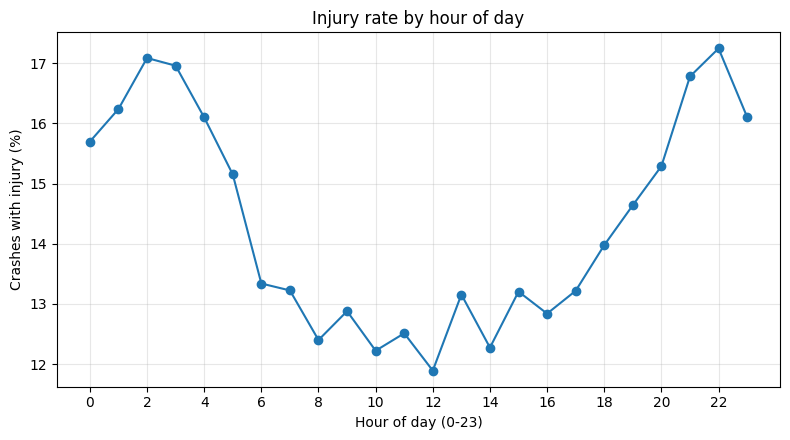

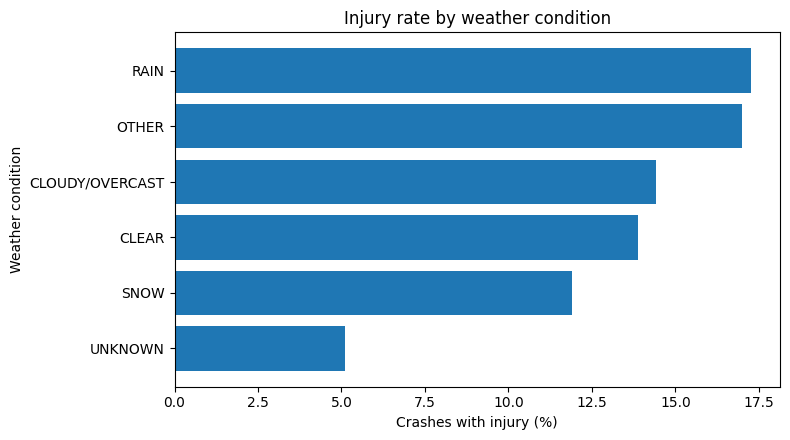

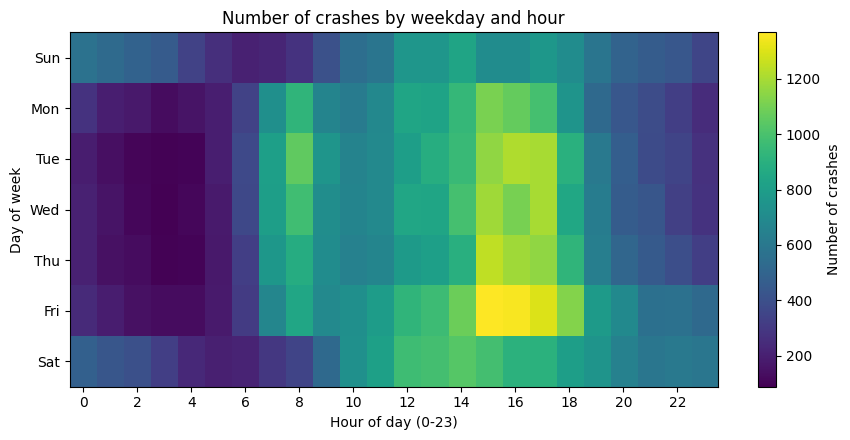


--- injury_by_lighting ---
    LIGHTING_CONDITION  crashes  injury_rate_pct
DARKNESS, LIGHTED ROAD    21928             17.2
                  DAWN     1676             15.6
                  DUSK     2875             13.6
              DAYLIGHT    64094             13.2
              DARKNESS     4712             12.5
               UNKNOWN     4512              3.9

--- injury_by_weekday_join ---
 day_name  crashes  injury_rate_pct
   Sunday    12464             15.2
 Thursday    14173             13.9
Wednesday    14203             13.6
   Monday    13536             13.6
 Saturday    14774             13.3
   Friday    16298             13.3
  Tuesday    14349             13.0

CELL 2 DONE. Part A is complete.


In [4]:
# Name: YOUR NAME | Roll no: YOUR ROLL NO | Date: 19 Nov 2026
# CELL 2 of 3: pipeline + quality gate, Pandas/NumPy analysis, 3 charts, SQLite
def avg_missing_pct(df):
    """Average % of missing cells per column."""
    return float(df.isna().mean().mean() * 100)


def run_pipeline(raw_df, threshold, metrics_path, save=True):
    """Check columns, apply the quality gate, clean, validate, save. Returns (cleaned, metrics)."""
    check_required_columns(raw_df, REQUIRED)
    pass_rate = validation_pass_rate(raw_df)
    dup = int(raw_df.duplicated(subset=[ID_COL]).sum()) if ID_COL else int(raw_df.duplicated().sum())
    metrics = {"rows_raw": int(len(raw_df)), "columns_raw": int(raw_df.shape[1]),
               "missing_pct_before": round(avg_missing_pct(raw_df), 2), "duplicate_ids_in_raw": dup,
               "validation_pass_rate": round(pass_rate, 4), "threshold": threshold}
    if pass_rate < threshold:
        metrics["quality_gate"] = "FAILED"
        metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
        raise QualityGateError(f"Pass rate {pass_rate:.1%} is below threshold {threshold:.0%}")
    cleaned = clean_all(raw_df)
    validate_cleaned(cleaned)
    metrics.update({"rows_clean": int(len(cleaned)), "columns_clean": int(cleaned.shape[1]),
                    "rows_removed_total": int(len(raw_df) - len(cleaned)),
                    "columns_dropped": sorted(set(raw_df.columns) - set(cleaned.columns)),
                    "missing_pct_after": round(avg_missing_pct(cleaned), 2),
                    "injury_rate_pct": round(float(cleaned["HAS_INJURY"].mean() * 100), 2),
                    "quality_gate": "PASSED"})
    metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    if save:
        cleaned.to_csv(BASE / "data/cleaned/crashes_clean.csv", index=False)
        table = ["# Data-quality report", "", "| Metric | Value |", "|---|---|"]
        table += [f"| {k} | {v} |" for k, v in metrics.items()]
        (REP / "data_quality_report.md").write_text("\n".join(table), encoding="utf-8")
    return cleaned, metrics


# Quality-gate threshold: 3 points below the real pass rate (real data passes, corrupted data fails)
real_rate = validation_pass_rate(raw)
PASS_THRESHOLD = round(min(0.90, real_rate - 0.03), 2)
print(f"Real validation pass rate: {real_rate:.1%} | chosen threshold: {PASS_THRESHOLD:.0%}")

clean, metrics = run_pipeline(raw, PASS_THRESHOLD, REP / "metrics.json")
print(json.dumps(metrics, indent=2))

# Show the gate failing on a deliberately corrupted COPY (the raw data is not touched)
bad = raw.copy()
bad.loc[bad.sample(frac=0.3, random_state=0).index, "POSTED_SPEED_LIMIT"] = 999
try:
    run_pipeline(bad, PASS_THRESHOLD, REP / "metrics_corrupted.json", save=False)
    print("ERROR: the gate should have failed")
except QualityGateError as err:
    print("QUALITY GATE FAILED as expected on corrupted data ->", err)

# ---------- Pandas + NumPy analysis ----------
df = clean.dropna(subset=["CRASH_HOUR", "CRASH_DAY_OF_WEEK"]).astype({"CRASH_HOUR": int, "CRASH_DAY_OF_WEEK": int}).copy()
df["IS_RUSH_HOUR"] = np.where(np.isin(df["CRASH_HOUR"].to_numpy(), [7, 8, 9, 16, 17, 18]), 1, 0)   # NumPy op 1
speed = df["POSTED_SPEED_LIMIT"].to_numpy(dtype=float)
df["SPEED_BAND"] = np.select([np.isnan(speed), speed < 25, speed < 35],
                             ["UNKNOWN", "LOW (<25)", "MEDIUM (25-34)"], default="HIGH (35+)")      # NumPy op 2

by_hour = df.groupby("CRASH_HOUR").agg(crashes=("HAS_INJURY", "size"), injury_rate_pct=("HAS_INJURY", "mean"))
by_hour["injury_rate_pct"] *= 100
by_weather = df.groupby("WEATHER_CONDITION").agg(crashes=("HAS_INJURY", "size"), injury_rate_pct=("HAS_INJURY", "mean"))
by_weather["injury_rate_pct"] *= 100
by_weather = by_weather[by_weather["crashes"] >= 200].sort_values("crashes", ascending=False)
day_hour = df.pivot_table(index="CRASH_DAY_OF_WEEK", columns="CRASH_HOUR", values="HAS_INJURY", aggfunc="size", fill_value=0)
rush_speed = df.groupby(["IS_RUSH_HOUR", "SPEED_BAND"]).agg(crashes=("HAS_INJURY", "size"),
                                                              injury_rate=("HAS_INJURY", "mean")).round(3)
crash_types = df["FIRST_CRASH_TYPE"].value_counts().head(10)
for name, tab in {"by_hour": by_hour, "by_weather": by_weather, "day_hour": day_hour,
                  "rush_speed": rush_speed, "crash_types": crash_types}.items():
    tab.to_csv(REP / f"summary_{name}.csv")
print(rush_speed)

# ---------- 3 charts ----------
captions = {}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_hour.index, by_hour["injury_rate_pct"], marker="o")
ax.set(title="Injury rate by hour of day", xlabel="Hour of day (0-23)", ylabel="Crashes with injury (%)")
ax.set_xticks(range(0, 24, 2)); ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig(FIG / "injury_rate_by_hour.png", dpi=150); plt.show()
captions["injury_rate_by_hour.png"] = "Share of crashes that involve an injury, for each hour of the day."

top = by_weather.head(8).sort_values("injury_rate_pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top["injury_rate_pct"])
ax.set(title="Injury rate by weather condition", xlabel="Crashes with injury (%)", ylabel="Weather condition")
fig.tight_layout(); fig.savefig(FIG / "injury_rate_by_weather.png", dpi=150); plt.show()
captions["injury_rate_by_weather.png"] = "Injury rate for the eight most common weather conditions."

grid = day_hour.reindex(index=range(1, 8), columns=range(24), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
img = ax.imshow(grid.to_numpy(), aspect="auto", cmap="viridis")
ax.set_yticks(range(7)); ax.set_yticklabels(["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"])
ax.set_xticks(range(0, 24, 2))
ax.set(title="Number of crashes by weekday and hour", xlabel="Hour of day (0-23)", ylabel="Day of week")
fig.colorbar(img, ax=ax, label="Number of crashes"); fig.tight_layout()
fig.savefig(FIG / "crashes_weekday_hour_heatmap.png", dpi=150); plt.show()
captions["crashes_weekday_hour_heatmap.png"] = "Crash counts by weekday and hour; the busiest times are weekday rush hours."

# ---------- SQLite: one GROUP BY query and one JOIN ----------
SQL1 = ("-- Which lighting conditions have the highest injury rate?\n"
        "SELECT LIGHTING_CONDITION, COUNT(*) AS crashes,\n"
        "       ROUND(100.0 * SUM(HAS_INJURY) / COUNT(*), 1) AS injury_rate_pct\n"
        "FROM crashes GROUP BY LIGHTING_CONDITION HAVING COUNT(*) >= 200\n"
        "ORDER BY injury_rate_pct DESC;")
SQL2 = ("-- Join crashes to a weekday lookup table to show readable day names.\n"
        "SELECT w.day_name, COUNT(*) AS crashes,\n"
        "       ROUND(100.0 * SUM(c.HAS_INJURY) / COUNT(*), 1) AS injury_rate_pct\n"
        "FROM crashes AS c JOIN weekday_lookup AS w ON c.CRASH_DAY_OF_WEEK = w.day_num\n"
        "GROUP BY w.day_name ORDER BY injury_rate_pct DESC;")
(BASE / "sql/injury_by_lighting.sql").write_text(SQL1, encoding="utf-8")
(BASE / "sql/injury_by_weekday_join.sql").write_text(SQL2, encoding="utf-8")
con = sqlite3.connect(BASE / "outputs/crashes.db")
df.assign(CRASH_DATE=df["CRASH_DATE"].astype(str)).to_sql("crashes", con, if_exists="replace", index=False)
days = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
pd.DataFrame({"day_num": range(1, 8), "day_name": days}).to_sql("weekday_lookup", con, if_exists="replace", index=False)
sql_results = {}
for name, query in {"injury_by_lighting": SQL1, "injury_by_weekday_join": SQL2}.items():
    sql_results[name] = pd.read_sql_query(query, con)
    sql_results[name].to_csv(REP / f"sql_{name}.csv", index=False)
    print(f"\n--- {name} ---\n{sql_results[name].to_string(index=False)}")
con.close()
print("\nCELL 2 DONE. Part A is complete.")

Target HAS_INJURY: injury rate 13.7% | 18 features
Cross-validating: Baseline (most frequent)
Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: Hist Gradient Boosting
Tuning Hist Gradient Boosting (train only)...
                         model  cv_precision  cv_recall  cv_f1  cv_roc_auc  cv_pr_auc
      Baseline (most frequent)         0.000      0.000  0.000       0.500      0.137
           Logistic Regression         0.305      0.734  0.431       0.820      0.514
                 Random Forest         0.410      0.579  0.480       0.824      0.511
        Hist Gradient Boosting         0.332      0.715  0.453       0.830      0.527
Hist Gradient Boosting (tuned)         0.325      0.723  0.448       0.828      0.525
{
  "chosen_model": "Hist Gradient Boosting",
  "precision": 0.3308,
  "recall": 0.7228,
  "f1": 0.4539,
  "roc_auc": 0.8291,
  "pr_auc": 0.5296,
  "no_skill_pr_auc": 0.1368
}


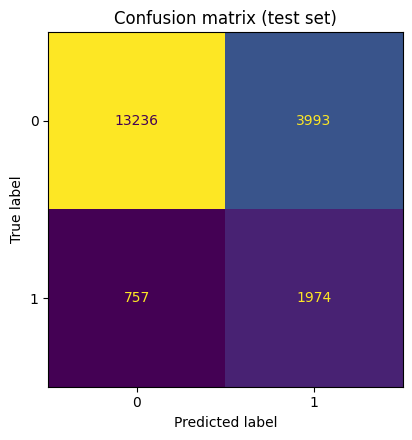

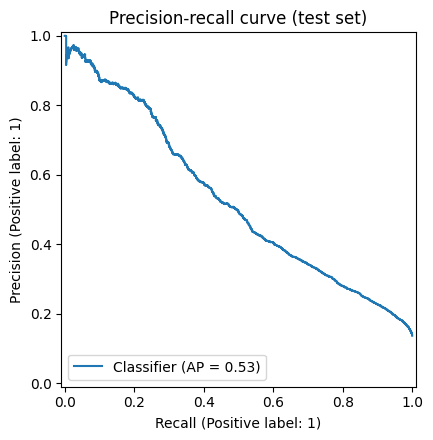

# Error analysis

False negatives: 757 | False positives: 3993

## Injury crashes the model missed
```
 proba  POSTED_SPEED_LIMIT         FIRST_CRASH_TYPE     LIGHTING_CONDITION        DAMAGE
 0.024                 NaN     PARKED MOTOR VEHICLE               DAYLIGHT   OVER $1,500
 0.028                10.0     PARKED MOTOR VEHICLE               DAYLIGHT $501 - $1,500
 0.031                30.0     PARKED MOTOR VEHICLE               DAYLIGHT $501 - $1,500
 0.033                20.0 SIDESWIPE SAME DIRECTION                UNKNOWN $501 - $1,500
 0.034                10.0     PARKED MOTOR VEHICLE DARKNESS, LIGHTED ROAD   OVER $1,500
 0.037                40.0     PARKED MOTOR VEHICLE DARKNESS, LIGHTED ROAD   OVER $1,500
 0.039                15.0     PARKED MOTOR VEHICLE DARKNESS, LIGHTED ROAD $501 - $1,500
 0.040                30.0     PARKED MOTOR VEHICLE               DAYLIGHT  $500 OR LESS
 0.044                30.0     PARKED MOTOR VEHICLE               DARKNESS $501 - $1,500
 0.045 

In [6]:
# Name: YOUR NAME | Roll no: YOUR ROLL NO | Date: 19 Nov 2026
# CELL 3 of 3: Part B (split first, one pipeline, compare models, error analysis, save, predict), Part C, docs
TARGET = "HAS_INJURY"
NUMERIC = ["POSTED_SPEED_LIMIT", "LANE_CNT", "NUM_UNITS", "CRASH_HOUR", "CRASH_DAY_OF_WEEK", "CRASH_MONTH",
           "LATITUDE", "LONGITUDE"]
CATEGORICAL = ["TRAFFIC_CONTROL_DEVICE", "WEATHER_CONDITION", "LIGHTING_CONDITION", "FIRST_CRASH_TYPE",
               "TRAFFICWAY_TYPE", "ALIGNMENT", "ROADWAY_SURFACE_COND", "ROAD_DEFECT", "INTERSECTION_RELATED_I",
               "HIT_AND_RUN_I", "DAMAGE"]
LEAKY = ["INJURIES_TOTAL", "INJURIES_FATAL", "INJURIES_INCAPACITATING", "INJURIES_NON_INCAPACITATING",
         "INJURIES_REPORTED_NOT_EVIDENT", "INJURIES_NO_INDICATION", "INJURIES_UNKNOWN", "MOST_SEVERE_INJURY",
         "CRASH_TYPE", "PRIM_CONTRIBUTORY_CAUSE", "SEC_CONTRIBUTORY_CAUSE", "REPORT_TYPE"]
num = [c for c in NUMERIC if c in clean.columns]
cat = [c for c in CATEGORICAL if c in clean.columns]
features = num + cat
assert not set(features) & set(LEAKY), "A leaking column is in the feature list"
data = clean.copy()
for c in cat:
    data[c] = data[c].astype(object)
print(f"Target {TARGET}: injury rate {data[TARGET].mean():.1%} | {len(features)} features")

# 1) SPLIT FIRST (stratified: keeps the injury share equal in train and test)
x_train, x_test, y_train, y_test = train_test_split(data[features], data[TARGET], test_size=0.2,
                                                    stratify=data[TARGET], random_state=SEED)


def build_pipeline(model):
    """One pipeline object: imputation + scaling + one-hot encoding + model (fitted on train only)."""
    numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100,
                                                  sparse_output=False))])
    prep = ColumnTransformer([("num", numeric_pipe, num), ("cat", cat_pipe, cat)])
    return Pipeline([("prep", prep), ("model", model)])


models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
SCORING = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_row(name, pipe):
    """5-fold cross-validated scores on the TRAIN set only."""
    s = cross_validate(pipe, x_train, y_train, cv=cv, scoring=SCORING)
    return {"model": name, **{f"cv_{m}": s[f"test_{m}"].mean() for m in SCORING}}


rows = []
for name, model in models.items():
    print("Cross-validating:", name)
    rows.append(cv_row(name, build_pipeline(model)))

print("Tuning Hist Gradient Boosting (train only)...")
search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED)),
    {"model__learning_rate": [0.03, 0.05, 0.1, 0.2], "model__max_depth": [None, 4, 6, 8],
     "model__max_leaf_nodes": [15, 31, 63], "model__l2_regularization": [0.0, 0.1, 1.0]},
    n_iter=6, scoring="average_precision", cv=3, random_state=SEED, n_jobs=-1)
search.fit(x_train, y_train)
tuned = clone(search.best_estimator_)
rows.append(cv_row("Hist Gradient Boosting (tuned)", tuned))
results = pd.DataFrame(rows).round(3)
results.to_csv(REP / "model_comparison.csv", index=False)
print(results.to_string(index=False))

# 2) Pick the best by CV PR-AUC, fit on train, evaluate on the TEST set ONCE
best_name = results.sort_values("cv_pr_auc", ascending=False).iloc[0]["model"]
best = tuned if "tuned" in best_name else build_pipeline(models[best_name])
best.fit(x_train, y_train)
proba, pred = best.predict_proba(x_test)[:, 1], best.predict(x_test)
test_metrics = {"chosen_model": best_name, "precision": precision_score(y_test, pred),
                "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
                "roc_auc": roc_auc_score(y_test, proba), "pr_auc": average_precision_score(y_test, proba),
                "no_skill_pr_auc": float(y_test.mean())}
test_metrics = {k: v if isinstance(v, str) else round(float(v), 4) for k, v in test_metrics.items()}
(REP / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")
print(json.dumps(test_metrics, indent=2))

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
ax.set_title("Confusion matrix (test set)"); fig.tight_layout()
fig.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(6, 4.5))
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax)
ax.set_title("Precision-recall curve (test set)"); fig.tight_layout()
fig.savefig(FIG / "precision_recall_curve.png", dpi=150); plt.show()

# 3) Error analysis
test = x_test.copy()
test[TARGET] = y_test
test["proba"] = proba
test["pred"] = pred
test["hour_band"] = pd.cut(test["CRASH_HOUR"], [-1, 5, 11, 17, 23],
                           labels=["Night 0-5", "Morning 6-11", "Afternoon 12-17", "Evening 18-23"]).astype(str)


def subgroup_table(frame, col, min_n=100):
    """Recall and precision for each group of `col` that has at least min_n rows."""
    out = []
    for value, g in frame.groupby(col):
        if len(g) >= min_n:
            out.append({col: value, "n": len(g), "injury_rate": round(g[TARGET].mean(), 3),
                        "recall": round(recall_score(g[TARGET], g["pred"], zero_division=0), 3),
                        "precision": round(precision_score(g[TARGET], g["pred"], zero_division=0), 3)})
    return pd.DataFrame(out).sort_values("recall")


show = [c for c in ["proba", "POSTED_SPEED_LIMIT", "FIRST_CRASH_TYPE", "LIGHTING_CONDITION", "DAMAGE"] if c in test.columns]
fn = test[(test[TARGET] == 1) & (test["pred"] == 0)].sort_values("proba").head(10)
fp = test[(test[TARGET] == 0) & (test["pred"] == 1)].sort_values("proba", ascending=False).head(10)
imp_sample = test.sample(min(5000, len(test)), random_state=SEED)
perm = permutation_importance(best, imp_sample[features], imp_sample[TARGET], scoring="average_precision",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=features).sort_values(ascending=False)
parts = ["# Error analysis", "",
         f"False negatives: {int(((test[TARGET] == 1) & (test['pred'] == 0)).sum())} | "
         f"False positives: {int(((test[TARGET] == 0) & (test['pred'] == 1)).sum())}", "",
         "## Injury crashes the model missed", "```", fn[show].round(3).to_string(index=False), "```", "",
         "## No-injury crashes flagged as injury", "```", fp[show].round(3).to_string(index=False), "```", ""]
for col in ["hour_band", "LIGHTING_CONDITION", "WEATHER_CONDITION", "FIRST_CRASH_TYPE"]:
    if col in test.columns:
        parts += [f"## Performance by {col}", "```", subgroup_table(test, col).to_string(index=False), "```", ""]
parts += ["## Permutation importance (drop in PR-AUC, top 10)", "```", imp.head(10).round(4).to_string(), "```"]
(REP / "error_analysis.md").write_text("\n".join(parts), encoding="utf-8")
print("\n".join(parts[:12]))
print("\nTop features:\n", imp.head(5).round(4))

# 4) Save the pipeline and score rows it has never seen (bonus predict.py logic)
MODEL_FILE = BASE / "outputs/models/crash_pipeline.joblib"
joblib.dump(best, MODEL_FILE)


def predict_csv(input_path, output_path, model_path=MODEL_FILE):
    """Load the saved pipeline, validate columns, apply the same cleaning, write predictions."""
    pipe = joblib.load(model_path)
    required = list(pipe.feature_names_in_)
    new = pd.read_csv(input_path, low_memory=False)
    new.columns = [c.strip().upper() for c in new.columns]
    missing = [c for c in required if c not in new.columns]
    if missing:
        raise ValueError(f"Input is missing required columns: {missing}")
    x = fix_types(new[required].copy())
    x = cap_outliers(mark_invalid_values(x))
    x = fill_missing(standardise_categories(x))
    for col in categorical_columns(x):
        x[col] = x[col].astype(object)
    out = new.copy()
    out["injury_probability"] = pipe.predict_proba(x)[:, 1].round(4)
    out["predicted_injury"] = pipe.predict(x)
    out.to_csv(output_path, index=False)
    return out


new_pred = predict_csv(BASE / "data/new_rows_example.csv", REP / "predictions_unseen.csv")
actual = (pd.to_numeric(new_pred["INJURIES_TOTAL"], errors="coerce") > 0).astype(int)
print("\nUnseen rows scored:", len(new_pred), "| matches actual:", int((new_pred["predicted_injury"] == actual).sum()))
print(new_pred[["injury_probability", "predicted_injury"]].head())
pd.read_csv(BASE / "data/new_rows_example.csv").drop(columns=["POSTED_SPEED_LIMIT"]).to_csv(
    BASE / "data/bad_columns.csv", index=False)
print("Missing-column check works:", raises(ValueError, predict_csv, BASE / "data/bad_columns.csv", REP / "x.csv"))

# ---------- Part C1: feed query with and without an index, ranker, cache ----------
N_USERS, FOLLOWS, N_POSTS, NOW = 1000, 50, 100_000, 1_800_000_000
FEED_SQL = ("SELECT p.post_id, p.author_id, p.created_at, p.likes FROM posts p "
            "JOIN follows f ON f.followee_id = p.author_id WHERE f.follower_id = ? "
            "ORDER BY p.created_at DESC LIMIT ?")
rng = random.Random(SEED)
c1 = sqlite3.connect(":memory:")
c1.execute("PRAGMA automatic_index = OFF")
c1.executescript("CREATE TABLE follows (follower_id INTEGER, followee_id INTEGER);"
                 "CREATE TABLE posts (post_id INTEGER PRIMARY KEY, author_id INTEGER, created_at INTEGER, likes INTEGER);")
c1.executemany("INSERT INTO follows VALUES (?,?)",
               [(u, v) for u in range(N_USERS) for v in rng.sample(range(N_USERS), FOLLOWS)])
c1.executemany("INSERT INTO posts VALUES (?,?,?,?)",
               [(i, rng.randrange(N_USERS), NOW - rng.randrange(30 * 86400), rng.randrange(500)) for i in range(N_POSTS)])
c1_log = [f"{N_USERS} users, {N_USERS * FOLLOWS} follows, {N_POSTS} posts"]


def plan(label):
    """Log EXPLAIN QUERY PLAN for the feed query."""
    c1_log.append(f"EXPLAIN QUERY PLAN ({label}):")
    c1_log.extend("   " + r[-1] for r in c1.execute("EXPLAIN QUERY PLAN " + FEED_SQL, (1, 10)).fetchall())


def avg_ms(users):
    """Average milliseconds per feed query."""
    t0 = time.perf_counter()
    for u in users:
        c1.execute(FEED_SQL, (u, 10)).fetchall()
    return (time.perf_counter() - t0) / len(users) * 1000


plan("no index")
t_no = avg_ms(range(3))
c1_log.append(f"No index: {t_no:.1f} ms per query")
c1.execute("CREATE INDEX idx_follows ON follows(follower_id, followee_id)")
c1.execute("CREATE INDEX idx_posts_author_time ON posts(author_id, created_at DESC)")
plan("with indexes")
t_ix = avg_ms(range(100))
c1_log.append(f"With indexes: {t_ix:.2f} ms per query (speed-up about {t_no / t_ix:.0f}x)")


def rank_feed(user, k=10):
    """Top-k posts for a user from the 200 newest candidates, scored by likes and recency."""
    rows_ = c1.execute(FEED_SQL, (user, 200)).fetchall()
    return sorted(rows_, key=lambda r: r[3] / (((NOW - r[2]) / 3600) + 2) ** 1.5, reverse=True)[:k]


cache = {}
t0 = time.perf_counter(); cache[7] = rank_feed(7); first = (time.perf_counter() - t0) * 1000
t0 = time.perf_counter(); _ = cache[7]; second = (time.perf_counter() - t0) * 1000
c1_log.append(f"Ranked feed: first call {first:.2f} ms, cached call {second:.5f} ms; top ids {[r[0] for r in cache[7]]}")
(REP / "feed_experiment.txt").write_text("\n".join(c1_log), encoding="utf-8")
print("\n".join(c1_log))

# ---------- Part C2: CI workflow, PR template, CODEOWNERS, review checklist ----------
ci = ["name: CI", "on:", "  pull_request:", "  push:", "    branches: [main]", "jobs:", "  lint-and-test:",
      "    runs-on: ubuntu-latest", "    steps:", "      - uses: actions/checkout@v4",
      "      - uses: actions/setup-python@v5", "        with:", '          python-version: "3.11"',
      "          cache: pip", "      - run: pip install -r requirements.txt",
      "      - run: flake8 src tests --max-line-length 100", "      - run: python -m pytest -q"]
(BASE / ".github/workflows/ci.yml").write_text("\n".join(ci) + "\n", encoding="utf-8")
pr = ["## What does this PR do?", "", "## Why?", "", "## How was it tested?",
      "- [ ] pytest passes", "- [ ] Ran the pipeline end to end", "", "## Notes for the reviewer"]
(BASE / ".github/pull_request_template.md").write_text("\n".join(pr) + "\n", encoding="utf-8")
owners = ["* @your-github-username", "/src/ @your-github-username", "/tests/ @your-github-username"]
(BASE / ".github/CODEOWNERS").write_text("\n".join(owners) + "\n", encoding="utf-8")
checklist = ["# Review checklist", "- [ ] Tests added or updated and passing",
             "- [ ] No secrets or large data files committed", "- [ ] Names and comments are clear",
             "- [ ] No leakage in ML code (split before fitting)", "- [ ] README and docs updated"]
(BASE / "docs/review_checklist.md").write_text("\n".join(checklist) + "\n", encoding="utf-8")

# ---------- Docs (drafts: rewrite in your own words) ----------
assumptions = [
    "# Assumptions, limitations, risks and model card", "",
    "## Data cleaning assumptions",
    "- Blank Y/N flag columns mean 'N'; other blank text means 'UNKNOWN'.",
    "- Speed limit outside 5-80 mph, coordinates outside Chicago and hours outside 0-23 are invalid (set to missing).",
    f"- NUM_UNITS is capped at {NUM_UNITS_CAP}. Non-flag columns with more than {SPARSE_THRESHOLD:.0%} missing are dropped.",
    "- Not fixed on purpose: missing numeric values are imputed inside the ML pipeline (train data only) to avoid leakage.", "",
    "## Model card",
    f"- Target: HAS_INJURY (1 = at least one person injured). Injury rate: {metrics['injury_rate_pct']}%.",
    "- Intended use: help road-safety teams prioritise crash types, times and places. Not for decisions about individuals.",
    "- Leaking columns excluded: " + ", ".join(LEAKY) + ".",
    "- Split: stratified random 80/20 (classes are imbalanced; crashes treated as independent). A time-based split would be stricter.",
    "- Metrics: PR-AUC, recall, precision and F1, because accuracy is misleading with imbalanced classes.",
    f"- Chosen model: {test_metrics['chosen_model']} | test recall {test_metrics['recall']} | "
    f"precision {test_metrics['precision']} | PR-AUC {test_metrics['pr_auc']}.",
    f"- Limitations: only crashes reported to Chicago Police; reporting may differ by area; model trained on a {len(raw):,}-row sample.",
    "- Risks: do not use it to deny resources to an area or to judge individuals."]
(BASE / "docs/assumptions.md").write_text("\n".join(assumptions), encoding="utf-8")
expl = ["# Part C write-ups (write in your own words, list sources)", "", "## C1: feed query results", "```"]
expl += c1_log + ["```", "TODO: answer the guiding questions yourself.", "", "## C2", "TODO", "",
                  "## C3 (glossary of 10 terms + one trade-off)", "TODO", "", "## C4 (workflow + one-page design doc)", "TODO"]
(BASE / "docs/exploration.md").write_text("\n".join(expl), encoding="utf-8")

fig_md = "\n".join(f"![{k}](outputs/figures/{k})\n*{v}*\n" for k, v in captions.items())
readme = ["# Chicago Traffic Crashes: data pipeline and injury model",
          "Source: Chicago Data Portal (Chicago Police E-Crash), Kaggle mirror anoopjohny/traffic-crashes-crashes. "
          "Access date: 19 Nov 2026. Licence: TODO (check).",
          "AI tools used: TODO (list them here).", "", "## Run",
          "pip install -r requirements.txt, then run the scripts in order: sample, pipeline, analysis, train, "
          "error analysis, predict. Tests: python -m pytest.", "",
          "## Data quality (before/after)", "```", json.dumps(metrics, indent=2), "```", "", "## Figures", fig_md,
          "## SQL", "Query 1 (GROUP BY): sql/injury_by_lighting.sql. Query 2 (JOIN): sql/injury_by_weekday_join.sql.",
          "```", sql_results["injury_by_lighting"].to_string(index=False), "```",
          "TODO: explain in your own words what this result shows.", "",
          "## Model comparison", "```", results.to_string(index=False), "```",
          "Test metrics: " + json.dumps(test_metrics)]
(BASE / "README.md").write_text("\n".join(readme), encoding="utf-8")

shutil.make_archive("/kaggle/working/project", "zip", BASE)
print("\nCELL 3 DONE. Download /kaggle/working/project.zip from the Output tab. Files:")
for p in sorted(BASE.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(BASE))